In [1]:
print("Mobile Price Prediction Project Started Successfully!")

Mobile Price Prediction Project Started Successfully!


## Import required libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset Loaded

In [4]:
df = pd.read_excel("Processed_Flipdata.xlsx")

In [5]:
## Display of First 5 row

df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [6]:
## Dataset Shape

print("Dataset Shape:", df.shape)

Dataset Shape: (541, 12)


In [7]:
## Column names

print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_', 'Prize']


In [8]:
## Dataset information

print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    str    
 2   Colour         541 non-null    str    
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    str    
 7   Front Camera   541 non-null    str    
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    str    
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 50.8 KB


In [9]:
## Missing value in each column

print("Missing Values:")
print(df.isnull().sum())


Missing Values:
Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64


In [10]:
## Total Missing Value

print("\nTotal Missing Values:", df.isnull().sum().sum()) 


Total Missing Values: 0


In [11]:
## Duplicate records

duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 0


In [12]:
## Display all column names

for column in df.columns:
    print(column)

Unnamed: 0
Model
Colour
Memory
RAM
Battery_
Rear Camera
Front Camera
AI Lens
Mobile Height
Processor_
Prize


In [13]:
## Remove the unnecessary index column 

df = df.drop("Unnamed: 0", axis=1)

In [14]:
## Updated dataset

print("Updated Dataset Shape:", df.shape)


Updated Dataset Shape: (541, 11)


In [15]:
## Display of First 5 rows

df.head()

,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [19]:
## Datatype of all column

print(df.dtypes)

Model                str
Colour               str
Memory             int64
RAM                int64
Battery_           int64
Rear Camera          str
Front Camera         str
AI Lens            int64
Mobile Height    float64
Processor_           str
Prize              int64
dtype: object


## Check unique values in camera columns

In [20]:
print("Rear Camera Values:")
print(df["Rear Camera"].unique())

print("\nFront Camera Values:")
print(df["Front Camera"].unique())

Rear Camera Values:
<StringArray>
[ '13MP',  '50MP',   '8MP',  '40MP',  '32MP',  '48MP',  '64MP', '108MP',
   '0MP',   '2MP',  '12MP', '200MP',   '5MP',  '16MP']
Length: 14, dtype: str

Front Camera Values:
<StringArray>
[ '5MP', '16MP',  '8MP', '13MP',  '0MP', '32MP', '10MP', '50MP', '60MP',
 '20MP', '44MP',  '2MP', '12MP']
Length: 13, dtype: str


In [21]:
## Convert camera columns from text to numbers

df["Rear Camera"] = df["Rear Camera"].str.replace("MP", "", regex=False).astype(int)

df["Front Camera"] = df["Front Camera"].str.replace("MP", "", regex=False).astype(int)

In [22]:
## Check the updated data types

print("Updated Camera Data Types:")
print(df[["Rear Camera", "Front Camera"]].dtypes)

Updated Camera Data Types:
Rear Camera     int64
Front Camera    int64
dtype: object


In [23]:
## Display the first 5 rows

df[["Rear Camera", "Front Camera"]].head()

,Rear Camera,Front Camera
0,13,5
1,13,5
2,50,16
3,8,5
4,50,5


In [24]:
## Check final data types

print("Data Types:")
print(df.dtypes)

Data Types:
Model                str
Colour               str
Memory             int64
RAM                int64
Battery_           int64
Rear Camera        int64
Front Camera       int64
AI Lens            int64
Mobile Height    float64
Processor_           str
Prize              int64
dtype: object


In [25]:
## Check missing values again

print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64


In [26]:
## Check dataset shape

print("\nDataset Shape:", df.shape)


Dataset Shape: (541, 11)


## # Statistical summary of the dataset

In [27]:
df.describe()

,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Prize
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,110.550832,5.397412,4871.587800,46.110906,11.992606,0.062847,16.431201,16228.375231
std,60.600694,1.984923,780.148862,31.260416,9.053746,0.242911,2.523553,10793.588322
min,16.000000,2.000000,800.000000,0.000000,0.000000,0.000000,4.500000,920.000000
25%,64.000000,4.000000,5000.000000,13.000000,5.000000,0.000000,16.510000,9290.000000
50%,128.000000,6.000000,5000.000000,50.000000,8.000000,0.000000,16.710000,13499.000000
75%,128.000000,8.000000,5000.000000,50.000000,16.000000,0.000000,16.940000,19280.000000
max,256.000000,8.000000,7000.000000,200.000000,60.000000,1.000000,41.940000,80999.000000


## # Distribution of mobile prices

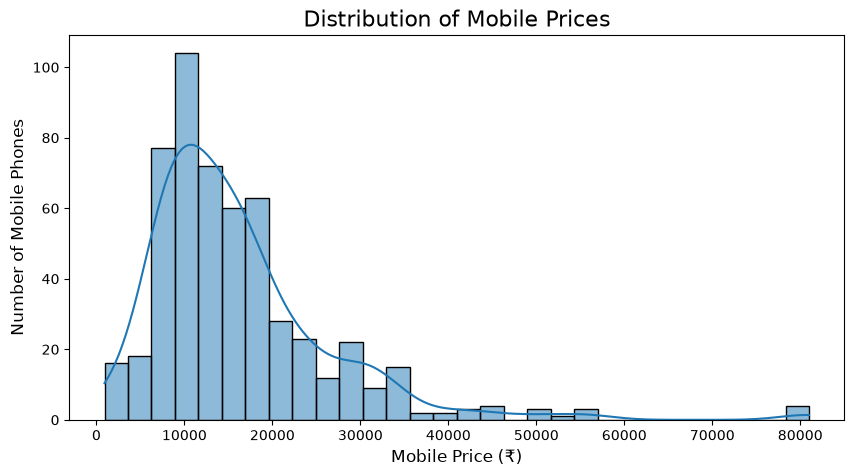

In [54]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Prize"], bins=30, kde=True)

plt.title("Distribution of Mobile Prices", fontsize=16)
plt.xlabel("Mobile Price (₹)", fontsize=12)
plt.ylabel("Number of Mobile Phones", fontsize=12)

plt.savefig("images/01_price_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## # Box plot of mobile prices

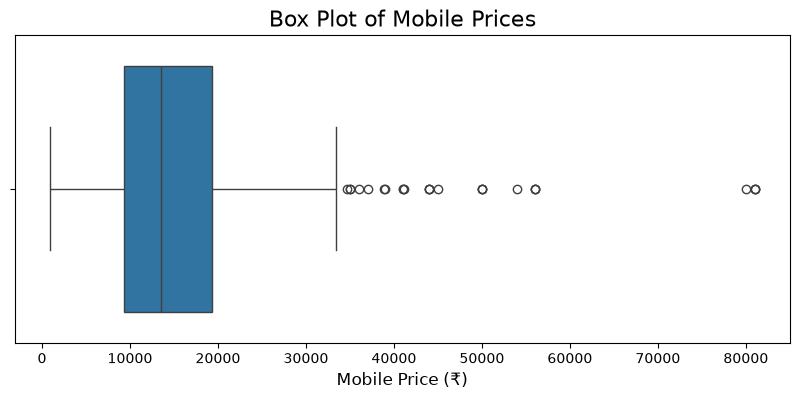

In [55]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Prize"])

plt.title("Box Plot of Mobile Prices", fontsize=16)
plt.xlabel("Mobile Price (₹)", fontsize=12)
plt.savefig("images/02_price_boxplot.png", dpi=300, bbox_inches="tight")

plt.savefig("images/02_price_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

## # Top 10 most common mobile models

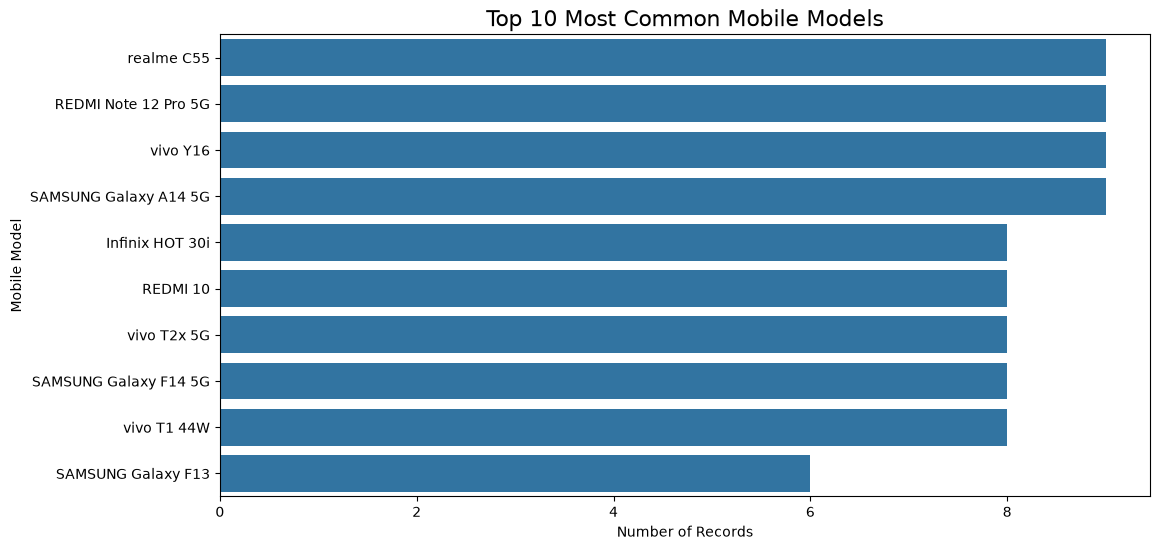

In [56]:
top_models = df["Model"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_models.values, y=top_models.index)

plt.title("Top 10 Most Common Mobile Models", fontsize=16)
plt.xlabel("Number of Records")
plt.ylabel("Mobile Model")

plt.savefig("images/03_top_mobile_models.png", dpi=300, bbox_inches="tight")
plt.show()

## # Average mobile price by RAM

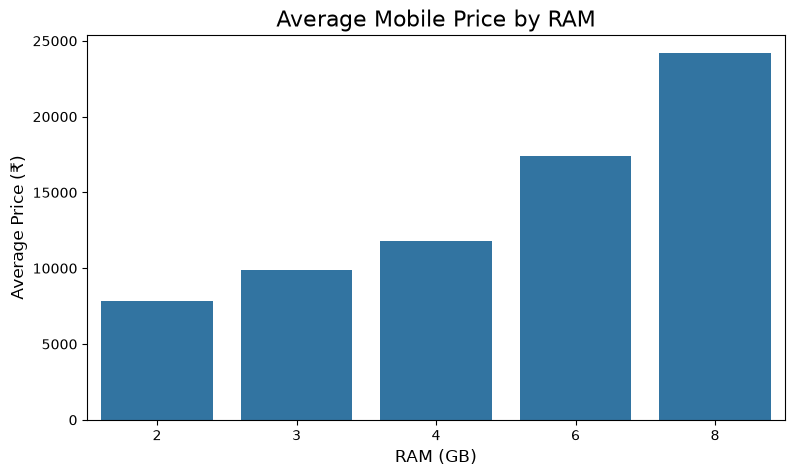

In [57]:
ram_price = df.groupby("RAM")["Prize"].mean().reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(data=ram_price, x="RAM", y="Prize")

plt.title("Average Mobile Price by RAM", fontsize=16)
plt.xlabel("RAM (GB)", fontsize=12)
plt.ylabel("Average Price (₹)", fontsize=12)

plt.savefig("images/04_average_price_by_ram.png", dpi=300, bbox_inches="tight")
plt.show()

## # Average mobile price by storage

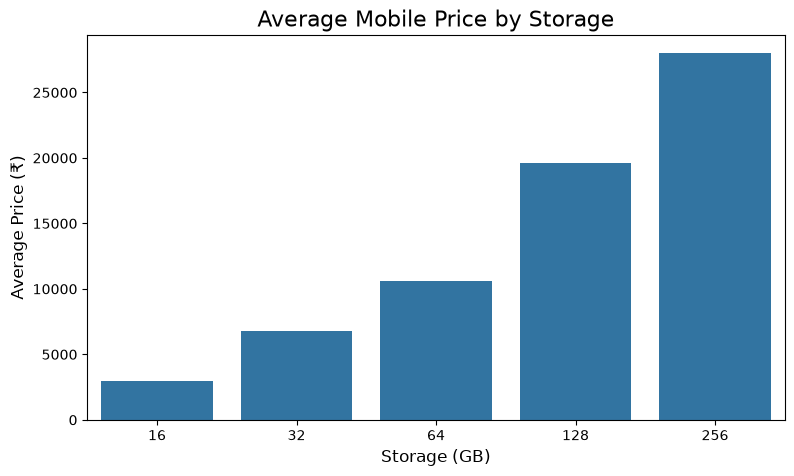

In [58]:
memory_price = df.groupby("Memory")["Prize"].mean().reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(data=memory_price, x="Memory", y="Prize")

plt.title("Average Mobile Price by Storage", fontsize=16)
plt.xlabel("Storage (GB)", fontsize=12)
plt.ylabel("Average Price (₹)", fontsize=12)

plt.savefig("images/05_average_price_by_storage.png", dpi=300, bbox_inches="tight")
plt.show()

## # Average mobile price by battery capacity

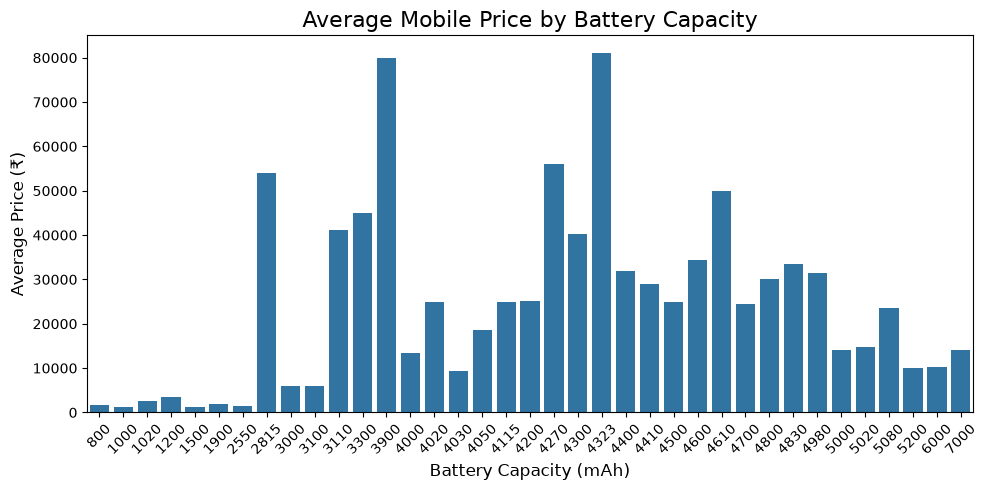

In [59]:
battery_price = df.groupby("Battery_")["Prize"].mean().reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(data=battery_price, x="Battery_", y="Prize")

plt.title("Average Mobile Price by Battery Capacity", fontsize=16)
plt.xlabel("Battery Capacity (mAh)", fontsize=12)
plt.ylabel("Average Price (₹)", fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("images/06_average_price_by_battery.png", dpi=300, bbox_inches="tight")
plt.show()

## # Average mobile price by processor

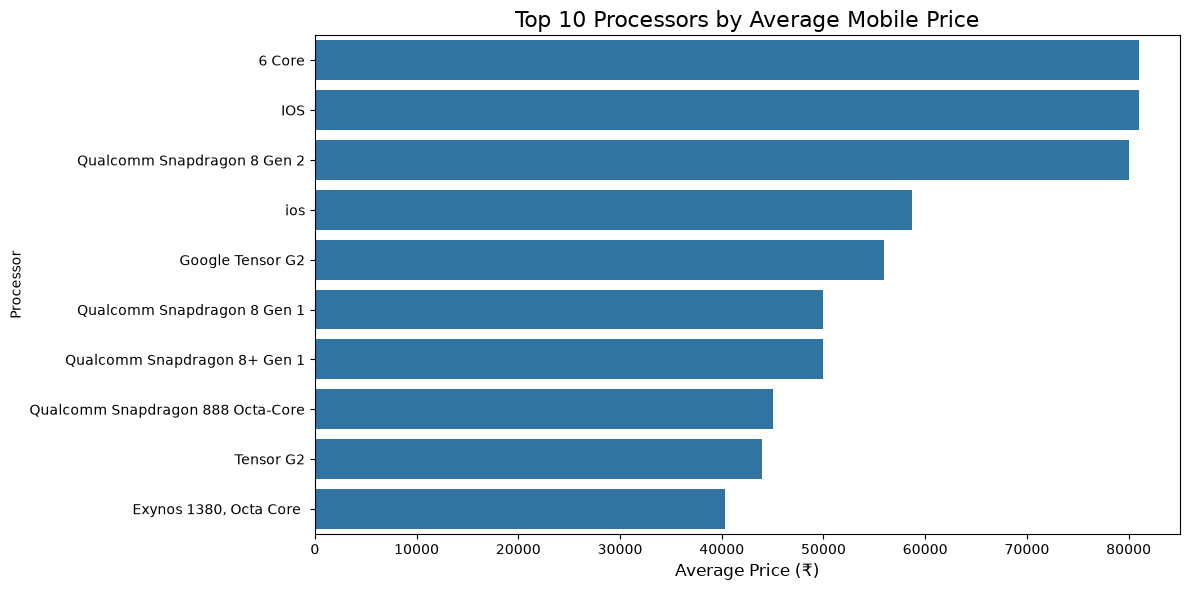

In [52]:
processor_price = df.groupby("Processor_")["Prize"].mean().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(data=processor_price, x="Prize", y="Processor_")

plt.title("Top 10 Processors by Average Mobile Price", fontsize=16)
plt.xlabel("Average Price (₹)", fontsize=12)
plt.ylabel("Processor")

plt.tight_layout()

plt.savefig("images/07_average_price_by_processor.png", dpi=300, bbox_inches="tight")
plt.show()

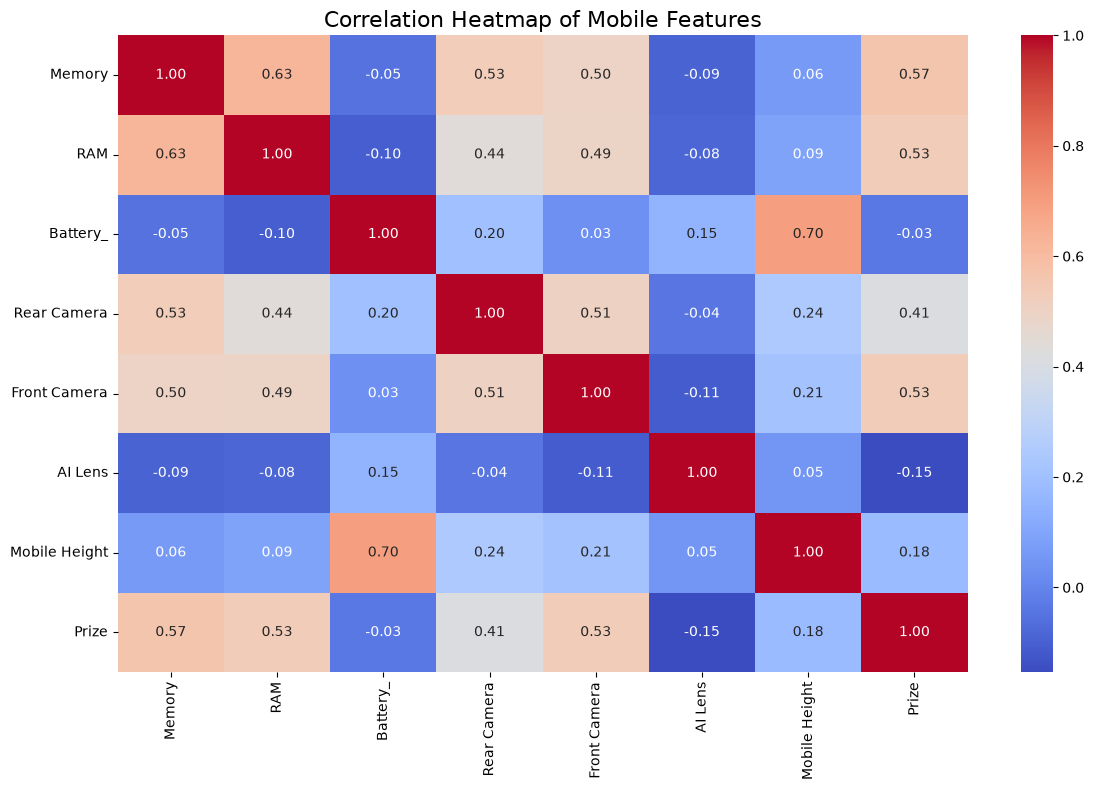

In [53]:
# Correlation heatmap

plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Mobile Features", fontsize=16)

plt.tight_layout()

plt.savefig("images/08_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

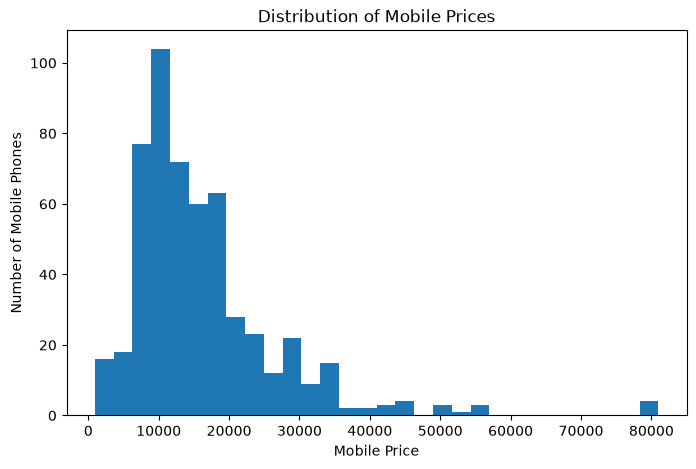

Graph saved successfully!


In [51]:
plt.figure(figsize=(8, 5))

plt.hist(df["Prize"], bins=30)

plt.title("Distribution of Mobile Prices")
plt.xlabel("Mobile Price")
plt.ylabel("Number of Mobile Phones")

plt.savefig("images/test_graph.png", dpi=300)
plt.show()

print("Graph saved successfully!")